# TPR reconstruction and steering

Results from the DISCOVER run at blocks **5, 12, 15, 24, 31**, comparing sentence-end and prompt-end activations. This notebook reads saved artifacts and needs no model weights or GPU.

Reconstruction measures free-running sentence recovery. Steering measures the original LLM’s pairwise answer preference: **patient logit − agent logit**. Positive changes favor the counterfactual answer. These are different tests of the decomposition.

In [1]:
%matplotlib inline
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if ROOT.name == 'notebook':
    ROOT = ROOT.parent
RUN = ROOT / 'ac-tpr-cache/tpr-discover-20261112-164912/pipeline'
reconstruction_metadata = json.loads((RUN / 'reconstruction/metadata.json').read_text())
steering_metadata = json.loads((RUN / 'steering/metadata.json').read_text())
reconstruction = pd.read_csv(RUN / 'reconstruction/results.csv')
steering = pd.read_csv(RUN / 'steering/results.csv')
baseline = pd.read_csv(RUN / 'steering/baseline.csv')
assert len(steering) == steering_metadata['result_rows']
assert len(baseline) == steering_metadata['baseline_rows']
LAYERS = steering_metadata['layer_indices']
SITES = steering_metadata['sites']
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.spines.top': False, 'axes.spines.right': False})
print('Run:', RUN)
print('Layers:', LAYERS, '| controls:', steering_metadata['controls'])
display(baseline.groupby(['source_tpr_split', 'target_tpr_split', 'voice']).size().rename('sentences').to_frame())

Run: /orfeo/cephfs/home/dssc/zenocosini/AC-TPR-project/ac-tpr-cache/tpr-discover-20261112-164912/pipeline
Layers: [5, 12, 15, 24, 31] | controls: {'zero_vector': 'passed', 'final_block_sentence_end': 'not evaluated', 'final_block_prompt_end_donor': 'not evaluated'}


sentences
source_tpr_split target_tpr_split voice             
binding_test     test             active          25
                                  passive         25
                 train            active         216
                                  passive        216
                 val              active          23
                                  passive         23
test             binding_test     active          25
                                  passive         25
                 test             active         158
                                  passive        158

## Training curves

Each curve shows validation loss, with one independently trained model per layer and capture site. Unpacker loss is token cross-entropy; TPR loss is mean squared error in standardized activation coordinates. Their scales are not comparable.

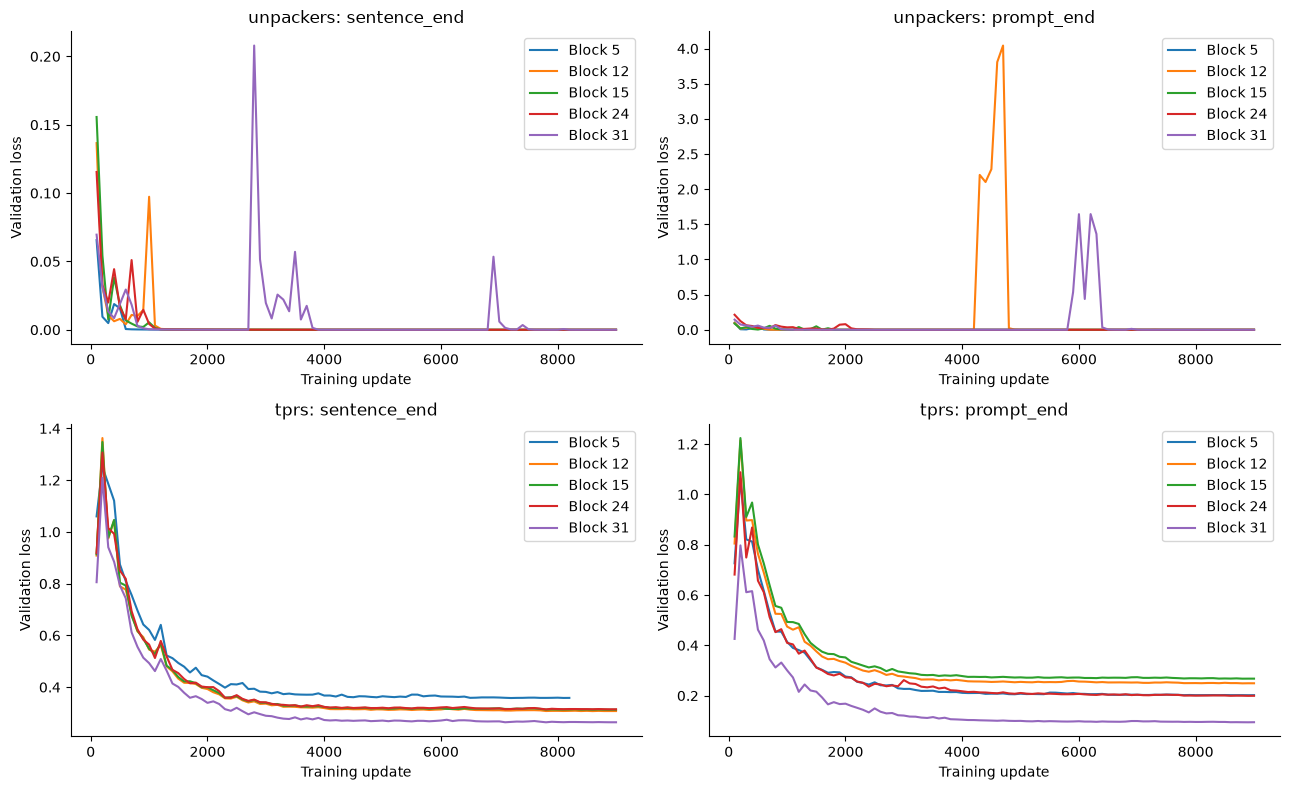

In [2]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), squeeze=False)
for row, stage in enumerate(['unpackers', 'tprs']):
    for col, site in enumerate(SITES):
        ax = axes[row, col]
        for layer in LAYERS:
            history = json.loads((RUN / stage / f'layer_{layer:02d}' / site / 'history.json').read_text())
            values = pd.DataFrame(history['evaluations'])
            ax.plot(values.step, values.validation_loss, label=f'Block {layer}')
        ax.set(title=f'{stage}: {site}', xlabel='Training update', ylabel='Validation loss')
        ax.legend()
fig.tight_layout()
plt.show()

## Sentence reconstruction

`real` decodes the original LLM activation; `tpr` decodes its symbolic approximation. The binding-test panel contains bindings withheld from both unpacker and TPR training. This is distinct from holding out the noun itself.

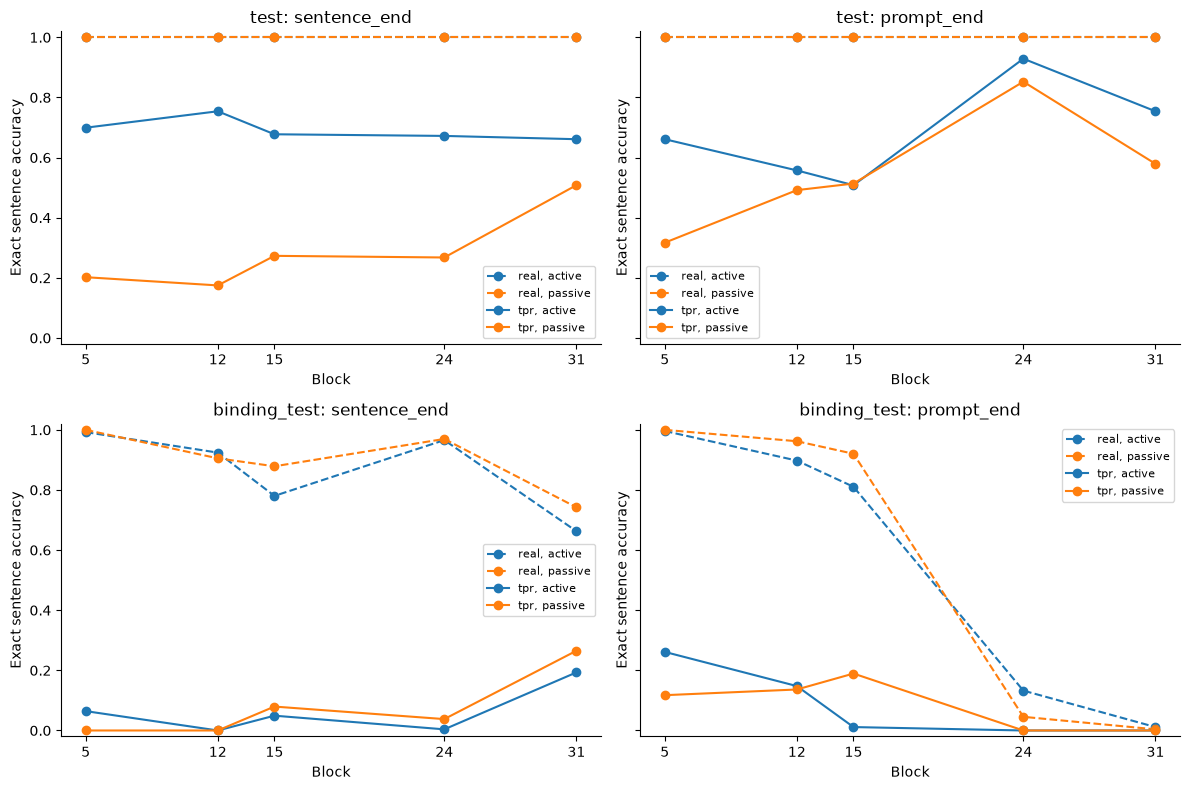

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True, squeeze=False)
for row, split in enumerate(['test', 'binding_test']):
    for col, site in enumerate(SITES):
        ax = axes[row, col]
        selected = reconstruction.query('tpr_split == @split and site == @site')
        for condition, style in [('real', '--'), ('tpr', '-')]:
            for voice, color in [('active', 'tab:blue'), ('passive', 'tab:orange')]:
                points = selected.query('condition == @condition and voice == @voice').groupby('layer').exact_match.mean()
                ax.plot(points.index, points, marker='o', linestyle=style, color=color, label=f'{condition}, {voice}')
        ax.set(title=f'{split}: {site}', xlabel='Block', ylabel='Exact sentence accuracy', ylim=(-.02, 1.02), xticks=LAYERS)
        ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Steering selection

Choose `novel_binding` to examine swaps **into** a withheld binding, `familiar_binding` for ordinary test sources whose targets also have familiar bindings, or `from_novel_binding` for the reverse direction. Counts below are the denominators, not independent repeated trials.

The default excludes training sources. Conditional flips count only sources initially favoring the agent; ties do not count as wins or flips. An undefined denominator is shown as NaN.

In [6]:
SELECTION = 'familiar_binding'  # novel_binding, familiar_binding, from_novel_binding
if SELECTION == 'novel_binding':
    selected = steering.loc[steering.target_binding_held_out & steering.source_tpr_split.eq('test')].copy()
elif SELECTION == 'familiar_binding':
    selected = steering.loc[~steering.target_binding_held_out & steering.source_tpr_split.eq('test')].copy()
elif SELECTION == 'from_novel_binding':
    selected = steering.loc[steering.source_tpr_split.eq('binding_test')].copy()
else:
    raise ValueError(SELECTION)
assert not selected.empty
selected['agent_win'] = selected.baseline_logit_diff < 0
selected['flip'] = selected.agent_win & (selected.intervened_logit_diff > 0)
summary = selected.groupby(['site', 'layer', 'voice', 'condition']).agg(
    sentences=('pair_id', 'size'), mean_change=('logit_diff_change', 'mean'),
    agent_wins=('agent_win', 'sum'), flips=('flip', 'sum'))
summary['conditional_flip_rate'] = summary.flips / summary.agent_wins.replace(0, np.nan)
display(summary.reset_index().query("condition == 'swap'"))

,site,layer,voice,condition,sentences,mean_change,agent_wins,flips,conditional_flip_rate
2,prompt_end,5,active,swap,158,0.012658,158,0,0.000000
6,prompt_end,5,passive,swap,158,-0.004747,158,0,0.000000
10,prompt_end,12,active,swap,158,0.009494,158,0,0.000000
14,prompt_end,12,passive,swap,158,-0.010285,158,0,0.000000
18,prompt_end,15,active,swap,158,0.000791,158,0,0.000000
22,prompt_end,15,passive,swap,158,0.011076,158,0,0.000000
26,prompt_end,24,active,swap,158,9.363924,158,46,0.291139
30,prompt_end,24,passive,swap,158,6.467563,158,62,0.392405
34,prompt_end,31,active,swap,158,14.656646,158,157,0.993671
38,prompt_end,31,passive,swap,158,12.212025,158,158,1.000000


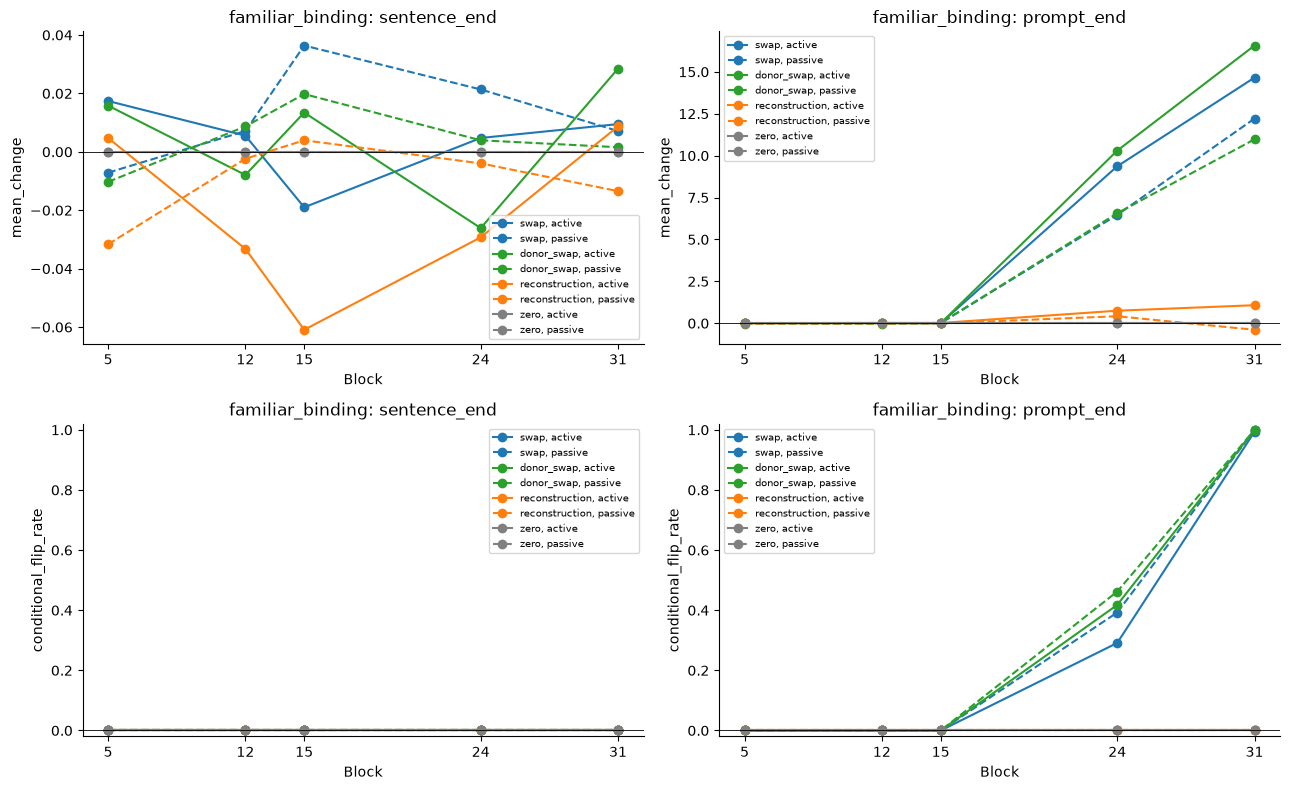

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), squeeze=False)
colors = {'swap': 'tab:blue', 'donor_swap': 'tab:green', 'reconstruction': 'tab:orange', 'zero': 'gray'}
for col, site in enumerate(SITES):
    for row, metric in enumerate(['mean_change', 'conditional_flip_rate']):
        ax = axes[row, col]
        for condition in colors:
            for voice, style in [('active', '-'), ('passive', '--')]:
                frame = summary.reset_index().query('site == @site and condition == @condition and voice == @voice')
                ax.plot(frame.layer, frame[metric], marker='o', color=colors[condition], linestyle=style, label=f'{condition}, {voice}')
        ax.axhline(0, color='black', linewidth=.6)
        ax.set(title=f'{SELECTION}: {site}', xlabel='Block', ylabel=metric, xticks=LAYERS)
        if row == 1: ax.set_ylim(-.02, 1.02)
        ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

`donor_swap` patches in the actual counterfactual sentence activation and tests the intervention site. `reconstruction` replaces the original activation with its TPR approximation without swapping. `zero` checks the hook. Compare these controls with the TPR swap before attributing an effect to symbolic structure.

Voice is confounded with the voice-specific demonstrations. All plots are descriptive averages of this corpus; they provide no uncertainty estimates.